In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. THIẾT LẬP ĐƯỜNG DẪN DỮ LIỆU CHUẨN
# ==========================================
# Lưu ý: Do file notebook nằm trong thư mục 'notebooks/', 
# ta phải lùi lại 1 thư mục gốc ('../') để vào 'data/processed/'
DATA_PATH = "../data/processed/telemetry_history.csv"

# ==========================================
# 2. HÀM ĐỌC HOẶC TẠO DỮ LIỆU MẪU (Mock Data)
# ==========================================
def load_or_mock_telemetry_data():
    if os.path.exists(DATA_PATH):
        print(f"[*] Đang tải dữ liệu thực tế từ: {DATA_PATH}")
        df = pd.read_csv(DATA_PATH)
    else:
        print(f"[!] Không tìm thấy {DATA_PATH}. Đang tạo dữ liệu mẫu để Demo EDA...")
        # Tạo dữ liệu giả lập cho 3 cục AP trong 14 tiếng (từ 6h sáng đến 20h tối)
        np.random.seed(42)
        hours = np.arange(6, 21)
        aps = ["AP_ThuVien", "AP_CangTin", "AP_HoiTruong"]
        
        data = []
        for ap in aps:
            for h in hours:
                # Giả lập: Căng tin nghẽn nặng lúc 11h-12h, Thư viện nghẽn lúc 9h và 14h
                base_pc = np.random.uniform(0.05, 0.15)
                if ap == "AP_CangTin" and h in [11, 12]: base_pc += np.random.uniform(0.4, 0.6)
                if ap == "AP_ThuVien" and h in [9, 14]: base_pc += np.random.uniform(0.3, 0.5)
                
                data.append({"Hour": h, "AP_Name": ap, "p_c": min(1.0, base_pc)})
        
        df = pd.DataFrame(data)
    return df

df = load_or_mock_telemetry_data()

# ==========================================
# 3. TIỀN XỬ LÝ DỮ LIỆU (Pivot Table)
# ==========================================
# Chuyển đổi DataFrame thành dạng Ma trận (Matrix) để vẽ Heatmap
# Trục tung (Index): Tên các AP
# Trục hoành (Columns): Các khung giờ trong ngày
# Giá trị (Values): Xác suất va chạm p_c
heatmap_data = df.pivot_table(index="AP_Name", columns="Hour", values="p_c", aggfunc=np.mean)

# ==========================================
# 4. TRỰC QUAN HÓA MULTIVARIATE: BẢN ĐỒ NHIỆT (HEATMAP)
# ==========================================
# Cấu hình phong cách biểu đồ chuẩn Báo cáo Khoa học
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Vẽ Heatmap siêu đẹp
# cmap="YlOrRd" tạo hiệu ứng chuyển từ Vàng (An toàn) -> Cam -> Đỏ đậm (Nghẽn nặng)
ax = sns.heatmap(
    heatmap_data, 
    cmap="YlOrRd", 
    annot=True,          # Hiển thị con số trên từng ô
    fmt=".2f",           # Lấy 2 chữ số thập phân
    linewidths=1.5,      # Thêm viền trắng giữa các ô cho sang trọng
    cbar_kws={'label': 'Xác suất va chạm tầng MAC ($p_c$)'}, # Ghi chú cột màu
    vmin=0.0, vmax=1.0   # Giới hạn thang đo từ 0% đến 100%
)

# Tinh chỉnh tiêu đề và nhãn
plt.title("BẢN ĐỒ NHIỆT (HEATMAP): Mật độ đụng độ Wi-Fi ($p_c$) theo Không gian và Thời gian", 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Khung giờ trong ngày (24h)", fontsize=12, fontweight='bold')
plt.ylabel("Khu vực phát sóng (AP)", fontsize=12, fontweight='bold')

# Xoay nhãn trục Y để dễ đọc
plt.yticks(rotation=0, fontsize=11)
plt.xticks(fontsize=11)

# Lưu ảnh chất lượng cao 300 DPI để dán vào Word/LaTeX báo cáo
plt.tight_layout()
os.makedirs("../wifi_rl_logs", exist_ok=True)
output_img = "../wifi_rl_logs/collision_heatmap.png"
plt.savefig(output_img, dpi=300)
print(f"✅ Đã lưu biểu đồ sắc nét tại: {output_img}")

# Hiển thị ngay trên Notebook
plt.show()

[*] Đang tải dữ liệu thực tế từ: ../data/processed/telemetry_history.csv


KeyError: 'AP_Name'

✅ Đã lưu biểu đồ phân tích Hành động AI tại: ../wifi_rl_logs/ai_actions_audit.png


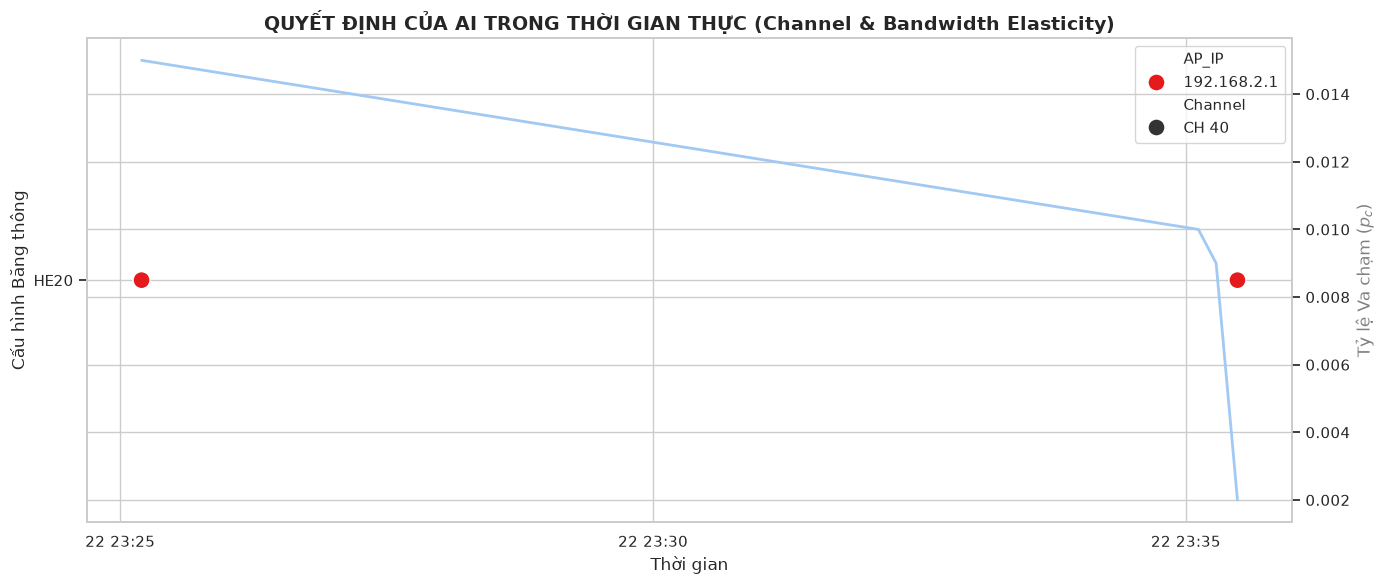

In [4]:
# ==========================================
# 5. TRỰC QUAN HÓA AI ACTIONS (REAL-TIME AUDIT)
# ==========================================
AI_LOG_PATH = "../data/processed/ai_actions_log.csv"

def visualize_ai_actions():
    if not os.path.exists(AI_LOG_PATH):
        print(f"[!] Chưa có file {AI_LOG_PATH}. Vui lòng bật AI Agent để sinh dữ liệu.")
        return

    df_ai = pd.read_csv(AI_LOG_PATH)
    if df_ai.empty:
        return
    
    df_ai['Timestamp'] = pd.to_datetime(df_ai['Timestamp'])
    
    # Lọc chỉ lấy các lệnh đã được thực thi (Executed)
    df_exec = df_ai[df_ai['Status'] == 'Executed'].copy()
    
    # Chuyển đổi Index thành Label dễ hiểu
    bw_map = {0: 'HE20', 1: 'HE40', 2: 'HE80'}
    ch_map = {0: 'CH 36', 1: 'CH 40', 2: 'CH 44'}
    df_exec['Bandwidth'] = df_exec['BW_Idx'].map(bw_map)
    df_exec['Channel'] = df_exec['CH_Idx'].map(ch_map)

    sns.set_theme(style="whitegrid")
    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Vẽ sự thay đổi Băng Thông theo Mức độ Nghẽn (p_c)
    sns.scatterplot(data=df_exec, x='Timestamp', y='Bandwidth', hue='AP_IP', style='Channel',
                    s=150, palette='Set1', ax=ax1)
    
    ax2 = ax1.twinx()
    sns.lineplot(data=df_ai, x='Timestamp', y='p_c', hue='AP_IP', palette='pastel', 
                 linewidth=2, ax=ax2, legend=False)

    ax1.set_title("QUYẾT ĐỊNH CỦA AI TRONG THỜI GIAN THỰC (Channel & Bandwidth Elasticity)", fontsize=14, fontweight='bold')
    ax1.set_xlabel("Thời gian", fontsize=12)
    ax1.set_ylabel("Cấu hình Băng thông", fontsize=12)
    ax2.set_ylabel("Tỷ lệ Va chạm ($p_c$)", fontsize=12, color='gray')
    
    plt.tight_layout()
    output_img = "../wifi_rl_logs/ai_actions_audit.png"
    plt.savefig(output_img, dpi=300)
    print(f"✅ Đã lưu biểu đồ phân tích Hành động AI tại: {output_img}")
    plt.show()

visualize_ai_actions()